In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print(train.shape)
print(test.shape)

train.head()

(1460, 81)
(1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


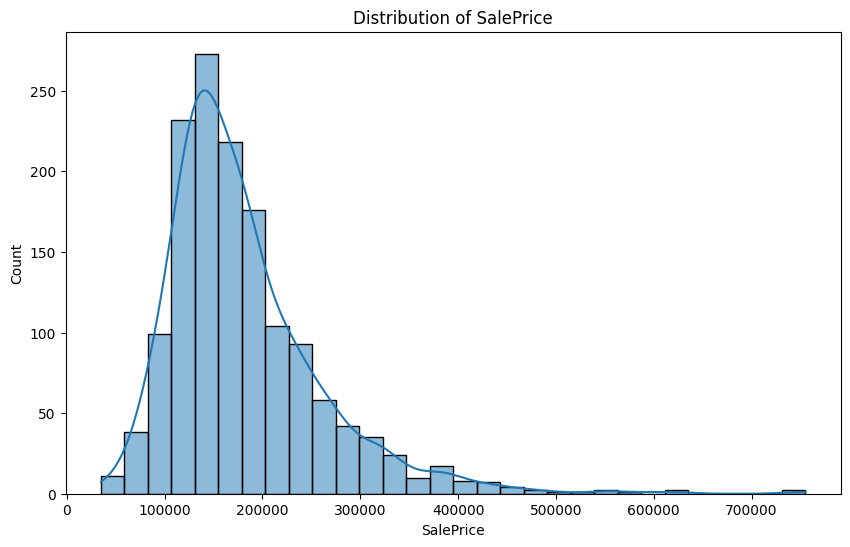

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [2]:
train['SalePrice'].describe()

plt.figure(figsize=(10, 6))
sns.histplot(train['SalePrice'], kde=True, bins=30)

plt.title('Distribution of SalePrice')
plt.show()

#missing value check
missing = train.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(missing)

In [113]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

numeric_cols = train.select_dtypes(include=[np.number]).columns
df = train[numeric_cols].dropna()
print(df.shape)
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_val)

print(f"R²: {r2_score(y_val, y_pred):.3f}")
print(f"MAE: {mean_absolute_error(y_val, y_pred):.0f}")

(1121, 55)
R²: 0.818
MAE: 22393


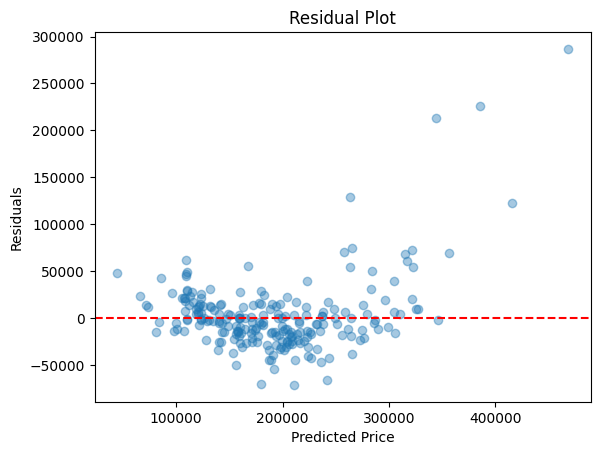

In [4]:
residuals = y_val - y_pred
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

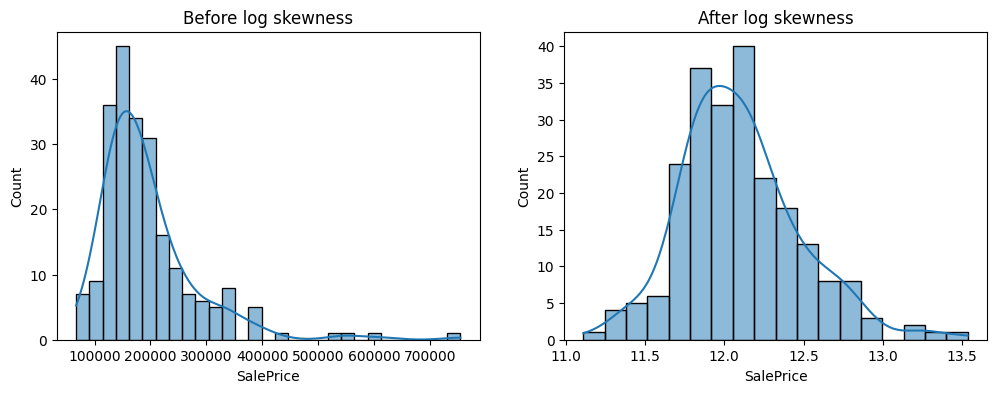

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_val, kde=True, ax=ax[0])
ax[0].set_title("Before log skewness")

sns.histplot(np.log1p(y_val), kde=True, ax=ax[1])
ax[1].set_title("After log skewness")
plt.show()

In [114]:
y = np.log1p(df['SalePrice'])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_val)

print(f"R²: {r2_score(y_val, y_pred):.3f}")

#convert to dollars
preds_actual = np.expm1(y_pred)
y_test_actual = np.expm1(y_val)
print(f"MAE: {mean_absolute_error(y_test_actual, preds_actual):.0f}")


R²: 0.881
MAE: 19560


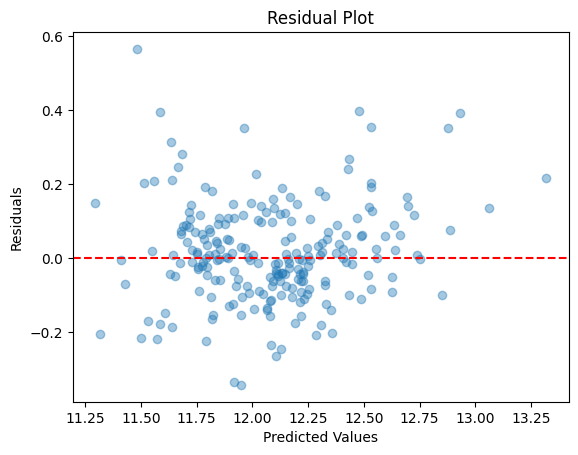

In [7]:
residuals = y_val - y_pred
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [8]:
categorical_cols = train.select_dtypes(include=["object", "string"]).columns
print(f"Categorical columns: {len(categorical_cols)}")
print(categorical_cols.tolist())

# Kaunse zyada important lag rahe hain — quick correlation check karte hain numeric ke through
train.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False).head()

Categorical columns: 43
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


Neighborhood
NoRidge    335295.317073
NridgHt    316270.623377
StoneBr    310499.000000
Timber     242247.447368
Veenker    238772.727273
Name: SalePrice, dtype: float64

In [9]:
cat_missing = train[categorical_cols].isnull().sum().sort_values(ascending=False)
print(cat_missing[cat_missing > 0])

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
GarageFinish      81
GarageQual        81
GarageType        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtQual          37
BsmtCond          37
Electrical         1
dtype: int64


In [10]:
train['MasVnrType'].value_counts(dropna=False)

MasVnrType
NaN        872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

In [11]:
train[['GarageType','GarageFinish', 'GarageQual','GarageCond']].isnull().sum()


GarageType      81
GarageFinish    81
GarageQual      81
GarageCond      81
dtype: int64

In [12]:
train[['BsmtQual','BsmtCond', 'BsmtExposure','BsmtFinType1', 'BsmtFinType2']].isnull().sum()

BsmtQual        37
BsmtCond        37
BsmtExposure    38
BsmtFinType1    37
BsmtFinType2    38
dtype: int64

In [13]:
train['MasVnrArea'].describe()

count    1452.000000
mean      103.685262
std       181.066207
min         0.000000
25%         0.000000
50%         0.000000
75%       166.000000
max      1600.000000
Name: MasVnrArea, dtype: float64

In [14]:
train['MasVnrArea'].isnull().sum()

np.int64(8)

In [76]:
#Garage
garage_cols = ['GarageType', 'GarageFinish', 'GarageQual','GarageCond']
for col in garage_cols:
    train[col] = train[col].fillna('NoGarage')
    
#basement
basement_cols = ['BsmtQual','BsmtCond', 'BsmtExposure','BsmtFinType1', 'BsmtFinType2']
for cols in basement_cols:
    train[cols] = train[cols].fillna('NoBasement')
    
# Others
train['PoolQC'] = train['PoolQC'].fillna('NoPool')
train['Fence'] = train['Fence'].fillna('NoFence')
train['Alley'] = train['Alley'].fillna('NoAlley')
train['FireplaceQu'] = train['FireplaceQu'].fillna('NoFireplace')
train['MiscFeature'] = train['MiscFeature'].fillna('None')
train['MasVnrType'] = train['MasVnrType'].fillna('None')
train['Electrical'] = train['Electrical'].fillna(train['Electrical'].mode()[0])


In [29]:
train[categorical_cols].isnull().sum().sort_values(ascending=False)

MSZoning         0
Street           0
Alley            0
LotShape         0
LandContour      0
Utilities        0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         0
BsmtCond         0
BsmtExposure     0
BsmtFinType1     0
BsmtFinType2     0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
KitchenQual      0
Functional       0
FireplaceQu      0
GarageType       0
GarageFinish     0
GarageQual       0
GarageCond       0
PavedDrive       0
PoolQC           0
Fence            0
MiscFeature      0
SaleType         0
SaleCondition    0
dtype: int64

In [30]:
train.groupby('KitchenQual')['SalePrice'].mean()

KitchenQual
Ex    328554.670000
Fa    105565.205128
Gd    212116.023891
TA    139962.511565
Name: SalePrice, dtype: float64

In [18]:
train.groupby('ExterQual')['SalePrice'].mean()

ExterQual
Ex    367360.961538
Fa     87985.214286
Gd    231633.510246
TA    144341.313466
Name: SalePrice, dtype: float64

In [19]:
train.groupby('BsmtQual')['SalePrice'].mean()

BsmtQual
Ex            327041.041322
Fa            115692.028571
Gd            202688.478964
NoBasement    105652.891892
TA            140759.818182
Name: SalePrice, dtype: float64

In [77]:
train.groupby('GarageType')['SalePrice'].mean()

GarageType
2Types      151283.333333
Attchd      202892.656322
Basment     160570.684211
BuiltIn     254751.738636
CarPort     109962.111111
Detchd      134091.162791
NoGarage    103317.283951
Name: SalePrice, dtype: float64

In [21]:
train.groupby('FireplaceQu')['SalePrice'].mean().sort_values()

FireplaceQu
Po             129764.150000
NoFireplace    141331.482609
Fa             167298.484848
TA             205723.488818
Gd             226351.415789
Ex             337712.500000
Name: SalePrice, dtype: float64

In [22]:
remaining_cat = train.select_dtypes(include=["object", "string"]).columns
print(f"Remaining categorical columns: {list(remaining_cat)}")

Remaining categorical columns: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [23]:
train['CentralAir'].value_counts()

CentralAir
Y    1365
N      95
Name: count, dtype: int64

In [24]:
train['PavedDrive'].value_counts()

PavedDrive
Y    1340
N      90
P      30
Name: count, dtype: int64

In [27]:
for col in [
    'ExterQual',
    'ExterCond',
    'BsmtQual',
    'BsmtCond',
    'HeatingQC',
    'KitchenQual',
    'FireplaceQu',
    'GarageQual',
    'GarageCond',
    'PoolQC'
]:
    print(col)
    print(train[col].unique())
    print()

ExterQual
<StringArray>
['Gd', 'TA', 'Ex', 'Fa']
Length: 4, dtype: str

ExterCond
<StringArray>
['TA', 'Gd', 'Fa', 'Po', 'Ex']
Length: 5, dtype: str

BsmtQual
<StringArray>
['Gd', 'TA', 'Ex', 'NoBasement', 'Fa']
Length: 5, dtype: str

BsmtCond
<StringArray>
['TA', 'Gd', 'NoBasement', 'Fa', 'Po']
Length: 5, dtype: str

HeatingQC
<StringArray>
['Ex', 'Gd', 'TA', 'Fa', 'Po']
Length: 5, dtype: str

KitchenQual
<StringArray>
['Gd', 'TA', 'Ex', 'Fa']
Length: 4, dtype: str

FireplaceQu
<StringArray>
['NoFireplace', 'TA', 'Gd', 'Fa', 'Ex', 'Po']
Length: 6, dtype: str

GarageQual
<StringArray>
['TA', 'Fa', 'Gd', 'NoGarbage', 'Ex', 'Po']
Length: 6, dtype: str

GarageCond
<StringArray>
['TA', 'Fa', 'NoGarbage', 'Gd', 'Po', 'Ex']
Length: 6, dtype: str

PoolQC
<StringArray>
['NoPool', 'Ex', 'Fa', 'Gd']
Length: 4, dtype: str



In [78]:
quality_map = {
    'Po': 0,
    'Fa': 1,
    'TA': 2,
    'Gd': 3,
    'Ex': 4
}

In [79]:
train['ExterQual'] = train['ExterQual'].map(quality_map)

In [80]:
train['ExterCond'] = train['ExterCond'].map(quality_map)

In [81]:
train['HeatingQC'] = train['HeatingQC'].map(quality_map)

In [82]:
train['KitchenQual'] = train['KitchenQual'].map(quality_map)

In [83]:
basement_map = {
    'NoBasement': 0,
    'Po': 1,
    'Fa': 2,
    'TA': 3,
    'Gd': 4,
    'Ex': 5
}

In [84]:
train['BsmtQual'] = train['BsmtQual'].map(basement_map)

In [85]:
train['BsmtCond'] = train['BsmtCond'].map(basement_map)

In [86]:
fireplace_map = {
    'NoFireplace': 0,
    'Po': 1,
    'Fa': 2,
    'TA': 3,
    'Gd': 4,
    'Ex': 5
}

In [87]:
train['FireplaceQu'] = train['FireplaceQu'].map(fireplace_map)

In [88]:
garage_map = {
    'NoGarage': 0,
    'Po': 1,
    'Fa': 2,
    'TA': 3,
    'Gd': 4,
    'Ex': 5
}

In [89]:
train['GarageQual'] = train['GarageQual'].map(garage_map)


In [90]:
train['GarageCond'] = train['GarageCond'].map(garage_map)

In [91]:
pool_map = {
    'NoPool': 0,
    'Fa': 1,
    'Gd': 2,
    'Ex': 3
}

In [92]:
train['PoolQC'] = train['PoolQC'].map(pool_map)

In [93]:
train[['ExterQual',
       'BsmtQual',
       'BsmtCond',
       'KitchenQual',
       'GarageQual',
       'PoolQC']].head()

,ExterQual,BsmtQual,BsmtCond,KitchenQual,GarageQual,PoolQC
0,3,4,3,3,3,0
1,2,4,3,2,3,0
2,3,4,3,3,3,0
3,2,3,4,3,3,0
4,3,4,3,3,3,0


In [95]:
train['CentralAir'].value_counts()

CentralAir
Y    1365
N      95
Name: count, dtype: int64

In [96]:
train['CentralAir'] = train['CentralAir'].map({'N': 0, 'Y': 1})

In [97]:
train.select_dtypes(include=['object','string']).columns

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'Foundation', 'BsmtExposure',
       'BsmtFinType1', 'BsmtFinType2', 'Heating', 'Electrical', 'Functional',
       'GarageType', 'GarageFinish', 'PavedDrive', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='str')

In [107]:
for col in [
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'GarageType',
    'GarageFinish',
    'PavedDrive',
    'Functional'
]:
    print("\n", col)
    print(train[col].value_counts())


 BsmtExposure
BsmtExposure
1    953
3    221
4    134
2    114
0     38
Name: count, dtype: int64

 BsmtFinType1
BsmtFinType1
1    430
6    418
5    220
4    148
3    133
2     74
0     37
Name: count, dtype: int64

 BsmtFinType2
BsmtFinType2
1    1256
3      54
2      46
0      38
4      33
5      19
6      14
Name: count, dtype: int64

 GarageType
GarageType
Attchd      870
Detchd      387
BuiltIn      88
NoGarage     81
Basment      19
CarPort       9
2Types        6
Name: count, dtype: int64

 GarageFinish
GarageFinish
1    605
2    422
3    352
0     81
Name: count, dtype: int64

 PavedDrive
PavedDrive
2    1340
0      90
1      30
Name: count, dtype: int64

 Functional
Functional
6    1360
4      34
5      31
3      15
2      14
1       5
0       1
Name: count, dtype: int64


In [99]:
bsmt_exposure_map = {
    'NoBasement':0,
    'No':1,
    'Mn':2,
    'Av':3,
    'Gd':4
}

train['BsmtExposure'] = train['BsmtExposure'].map(bsmt_exposure_map)

In [100]:
garage_finish_map = {
    'NoGarage':0,
    'Unf':1,
    'RFn':2,
    'Fin':3
}

train['GarageFinish'] = train['GarageFinish'].map(garage_finish_map)

In [101]:
paved_drive_map = {
    'N':0,
    'P':1,
    'Y':2
}

train['PavedDrive'] = train['PavedDrive'].map(paved_drive_map)

In [102]:
functional_map = {
    'Sev':0,
    'Maj2':1,
    'Maj1':2,
    'Mod':3,
    'Min2':4,
    'Min1':5,
    'Typ':6
}

train['Functional'] = train['Functional'].map(functional_map)

In [103]:
bsmt_fin_map = {
    'NoBasement':0,
    'Unf':1,
    'LwQ':2,
    'Rec':3,
    'BLQ':4,
    'ALQ':5,
    'GLQ':6
}

train['BsmtFinType1'] = train['BsmtFinType1'].map(bsmt_fin_map)

In [104]:
train['BsmtFinType2'] = train['BsmtFinType2'].map(bsmt_fin_map)

In [105]:
ordinal_cols = [
    'BsmtExposure',
    'GarageFinish',
    'PavedDrive',
    'Functional',
    'BsmtFinType1',
    'BsmtFinType2'
]

train[ordinal_cols].head()

,BsmtExposure,GarageFinish,PavedDrive,Functional,BsmtFinType1,BsmtFinType2
0,1,2,2,6,6,1
1,4,2,2,6,5,1
2,2,2,2,6,6,1
3,1,1,2,6,5,1
4,3,2,2,6,6,1


In [108]:
rem_cat = train.select_dtypes(include=['object','string']).columns
print(rem_cat)

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical',
       'GarageType', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition'],
      dtype='str')


In [109]:
#One hot
train = pd.get_dummies(train, columns=rem_cat, drop_first=True)

In [110]:
train.select_dtypes(include=['object']).columns

Index([], dtype='str')

In [120]:
train['LotFrontage'] = train['LotFrontage'].fillna(
    train['LotFrontage'].median()
)

In [121]:
train['MasVnrArea'] = train['MasVnrArea'].fillna(0)

In [122]:
train['GarageYrBlt'] = train['GarageYrBlt'].fillna(0)

In [124]:
nan_cols = X.columns[X.isnull().any()]
for col in nan_cols:
    print(col, X[col].isnull().sum())

LotFrontage 259
MasVnrArea 8
GarageYrBlt 81


In [125]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

X = train.drop('SalePrice', axis=1)
y = np.log1p(train['SalePrice'])
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
preds = model.predict(X_val)
print(f"R²: {r2_score(y_val, preds):.3f}")

R²: 0.775


In [126]:
y.head()

0    12.247699
1    12.109016
2    12.317171
3    11.849405
4    12.429220
Name: SalePrice, dtype: float64

In [127]:
print(train.shape)

(1460, 210)


In [128]:
train.select_dtypes(include=['object']).columns

Index([], dtype='str')

In [129]:
train.isnull().sum().sum()

np.int64(0)

In [130]:
print(train.shape)
print(train.isnull().sum().sum())

(1460, 210)
0


In [131]:
from sklearn.metrics import mean_absolute_error

actual = np.expm1(y_val)
predicted = np.expm1(preds)

print(mean_absolute_error(actual, predicted))

15484.800964061125


In [133]:
# Coefficients ka spread check karo
coefs = pd.Series(model.coef_, index=X.columns)
print("Top 10 extreme coefficients:")   
print(coefs.abs().sort_values(ascending=False).head(10))

Top 10 extreme coefficients:
RoofMatl_WdShngl    2.703571
RoofMatl_WdShake    2.629584
RoofMatl_Roll       2.625785
RoofMatl_CompShg    2.625430
RoofMatl_Metal      2.608084
RoofMatl_Tar&Grv    2.546597
Condition2_PosN     0.811088
MSZoning_FV         0.359862
MSZoning_RH         0.354757
MiscFeature_TenC    0.349366
dtype: float64


In [136]:
# Safe check for RoofMatl after get_dummies
if 'RoofMatl' in train.columns:
    print(train['RoofMatl'].value_counts())
else:
    dummy_cols = [c for c in train.columns if c.startswith('RoofMatl_')]
    if dummy_cols:
        # sum True/1 values to get counts per category
        print(train[dummy_cols].sum().sort_values(ascending=False))
    else:
        print("Column 'RoofMatl' not found (and no dummy columns present).")

RoofMatl_CompShg    1434
RoofMatl_Tar&Grv      11
RoofMatl_WdShngl       6
RoofMatl_WdShake       5
RoofMatl_Membran       1
RoofMatl_Metal         1
RoofMatl_Roll          1
dtype: int64


In [137]:
from sklearn.linear_model import Ridge, Lasso

ridge = Ridge(alpha=10.0)
ridge.fit(X_train, y_train)
preds_ridge = ridge.predict(X_val)

print(f"Ridge R²: {r2_score(y_val, preds_ridge):.3f}")
print(f"Ridge MAE: {mean_absolute_error(np.expm1(y_val), np.expm1(preds_ridge)):.0f}")

lasso = Lasso(alpha=0.001)
lasso.fit(X_train, y_train)
preds_lasso = lasso.predict(X_val)

print(f"Lasso R²: {r2_score(y_val, preds_lasso):.3f}")
print(f"Lasso MAE: {mean_absolute_error(np.expm1(y_val), np.expm1(preds_lasso)):.0f}")

Ridge R²: 0.900
Ridge MAE: 16392
Lasso R²: 0.893
Lasso MAE: 16577


In [139]:
ridge_coefs = pd.Series(ridge.coef_, index=X.columns)
print("Top 10 (Ridge):")
print(ridge_coefs.abs().sort_values(ascending=False).head(10))

Top 10 (Ridge):
Neighborhood_StoneBr    0.090160
Neighborhood_Crawfor    0.087693
Condition2_PosN         0.084219
Neighborhood_NridgHt    0.079590
Exterior1st_BrkFace     0.074444
LandContour_HLS         0.061787
Neighborhood_MeadowV    0.061043
OverallQual             0.055668
LotShape_IR3            0.054824
Neighborhood_Edwards    0.054480
dtype: float64


In [140]:
#cross validation
from sklearn.model_selection import cross_val_score

# Plain LR
lr_scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print(f"Plain LR - Mean R²: {lr_scores.mean():.3f}, Std: {lr_scores.std():.3f}")
print(f"All folds: {lr_scores}")

# Ridge
ridge_scores = cross_val_score(Ridge(alpha=10.0), X, y, cv=5, scoring='r2')
print(f"\nRidge - Mean R²: {ridge_scores.mean():.3f}, Std: {ridge_scores.std():.3f}")
print(f"All folds: {ridge_scores}")

# Lasso
lasso_scores = cross_val_score(Lasso(alpha=0.001), X, y, cv=5, scoring='r2')
print(f"\nLasso - Mean R²: {lasso_scores.mean():.3f}, Std: {lasso_scores.std():.3f}")
print(f"All folds: {lasso_scores}")

Plain LR - Mean R²: 0.771, Std: 0.147
All folds: [0.49434093 0.85858742 0.83819635 0.90994873 0.75467102]

Ridge - Mean R²: 0.872, Std: 0.050
All folds: [0.90734632 0.87612671 0.90343119 0.9012799  0.77397642]

Lasso - Mean R²: 0.872, Std: 0.055
All folds: [0.91108988 0.87443163 0.90712533 0.90153372 0.76469186]


In [141]:
#Save the model
import joblib

# Final Ridge model train (poore training data pe — sab numeric + categorical)
final_model = Ridge(alpha=10.0)
final_model.fit(X, y)

# Model save karo
joblib.dump(final_model, 'house_price_model.pkl')

# Columns ka list bhi save— Streamlit app ko pata hona chahiye kaunse columns chahiye
joblib.dump(X.columns.tolist(), 'model_columns.pkl')

# Median values bhi save missing value fill karne ke liye
medians = X.median()
joblib.dump(medians, 'feature_medians.pkl')

print("Saved! Files:", "house_price_model.pkl, model_columns.pkl, feature_medians.pkl")

Saved! Files: house_price_model.pkl, model_columns.pkl, feature_medians.pkl
